Step 1: Load the Cleaned Data

In [7]:
import pandas as pd

file_path = "merged_recipes.xlsx"
recipe_df = pd.read_excel(file_path)

recipe_df.head()


,Recipe Name,Ingredients,Cuisine Region,Cooking Method,Recipe,Category
0,Pulao,"Rice, Mutton/Beef, Whole Spices, Onions, Ginge...",Punjab,"Boiling, Simmering",Sauté onions and whole spices in ghee. Add mea...,Rice
1,Tahari,"Rice, Potatoes, Onions, Tomatoes, Green Chilie...",Punjab,One-Pot Cooking,Sauté onions and spices in ghee. Add potatoes ...,Rice
2,Saag Chawal,"Rice, Spinach, Mustard Greens, Green Chilies, ...",Punjab,"Boiling, Sautéing",Boil rice separately. Sauté spinach and mustar...,Rice
3,Machli Pulao,"Rice, Fish, Yogurt, Tomatoes, Onions, Green Ch...",Sindh,"Boiling, Simmering",Cook fish with spices and tomatoes. Boil rice ...,Rice
4,Chicken Qorma Pulao,"Rice, Chicken, Yogurt, Qorma Masala, Onions, G...",Punjab,"Boiling, Simmering","Cook chicken with qorma masala, onions, and yo...",Rice


Step 2: Import all the Packages 

In [8]:
import numpy as np
import re
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split



Step 3: Break the data into two parts:
X -> Input Features -> Ingredients
Y -> Output Features -> Recipe Name

Dividing the Data into Training and Testing Set

In [9]:

X = recipe_df['Ingredients']
y = recipe_df['Recipe Name']

#Update test size based on the number of classes
n_classes = len(y.unique())
test_size = min(234, len(recipe_df) // 5)  #ensuring that there is enough data for classes


# print("X:",X)

# print("Y:",y)

#Splitting the data into testing and training sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.4,      #40% of the dataset is used for testing
    random_state=42     #seed value for reproducability in random
)

#putting the data into vectors
vectorizer = TfidfVectorizer()
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

#printing sizes of datasets
print(f'Training set size: {X_train.shape[0]}')
print(f'Testing set size: {X_test.shape[0]}')


Training set size: 1983
Testing set size: 1322


Step 4: Loading Different Models from sci-kit learn

We will be evaluating the following Models:
1. Logistic Regression
2. Decision Tree
3. Random Forest
4. Support Vector Machine

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score

Step 5: Running Training and Testing on Dataset (with Accuracy issue)
Here, we were not able to calculate accuracy properly due to our approach which cannot match predictions with ground truth in a trivial way.

In [11]:
import pandas as pd
import re
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

#preprocessing data
def preprocess_ingredients(ingredients):
    ingredients = ingredients.lower()  #lowercase
    ingredients = re.sub(r'[^a-z\s]', '', ingredients)  #removing special characters 
    return ingredients

#creating a clear division of features and targets
recipe_df['Ingredients'] = recipe_df['Ingredients'].apply(preprocess_ingredients)
X = recipe_df['Ingredients']  #Features
y = recipe_df['Recipe Name']  #Target

#splitting dataset into test and train
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

#creating vectors
vectorizer = TfidfVectorizer(max_features=500)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

#defining all the models to be used
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Support Vector Machine': SVC()
}

#training the models and testing, evaluation
for model_name, model in models.items():
    model.fit(X_train_tfidf, y_train)  #Train
    y_pred = model.predict(X_test_tfidf)  #Predict
    accuracy = accuracy_score(y_test, y_pred)  #Accuracy

    print(f'{model_name} Accuracy: {accuracy:.2f}')  # Output


Logistic Regression Accuracy: 0.00
Decision Tree Accuracy: 0.00
Random Forest Accuracy: 0.00
Support Vector Machine Accuracy: 0.00


Step 5: Running Training and Testing on Dataset (with Cosine-Similarity Accuracy)

We were able to check how accurate our models are based on how similar the answers of ingredients the the recipe returned and ingredients of the recipe in the ground truth.

Logistic Regression Cosine Similarity-Based Accuracy: 0.70
Decision Tree Cosine Similarity-Based Accuracy: 0.30
Random Forest Cosine Similarity-Based Accuracy: 0.50
Support Vector Machine Cosine Similarity-Based Accuracy: 0.71


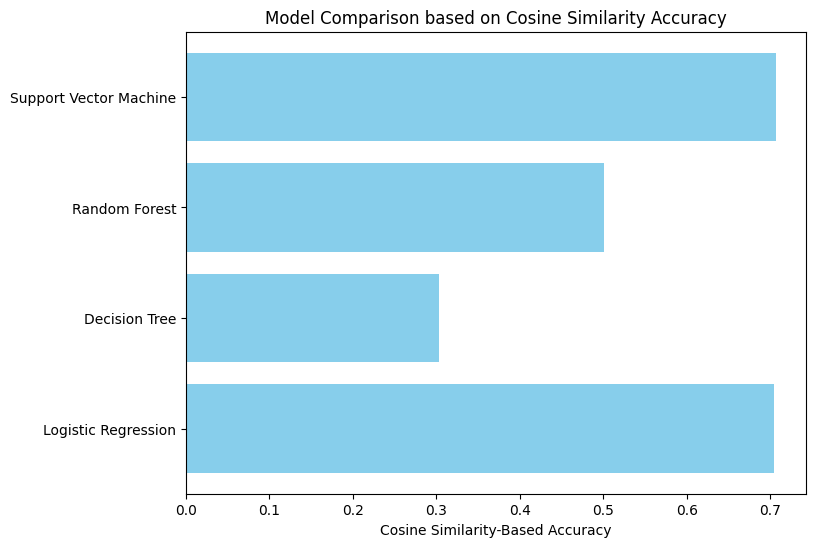

In [12]:
import pandas as pd
import re
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

#preprocessing data
def preprocess_ingredients(ingredients): 
    ingredients = ingredients.lower() #lowercase
    ingredients = re.sub(r'[^a-z\s]', '', ingredients)  #removing special characters
    return ingredients
#creating a division of ingredients and recipe
recipe_df['Ingredients'] = recipe_df['Ingredients'].apply(preprocess_ingredients)
X = recipe_df['Ingredients']  #Features
y = recipe_df['Recipe Name']  #Target

# creating a dictionary to map recipe to ingredients
recipe_to_ingredients = dict(zip(recipe_df['Recipe Name'], recipe_df['Ingredients']))

#splitting the dataset
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

#vectorizing the data
vectorizer = TfidfVectorizer(max_features=500)
X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

#defining models to be used
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(),
    'Random Forest': RandomForestClassifier(),
    'Support Vector Machine': SVC()
}

#cosine similarity threshold for determining "accuracy"
cosine_threshold = 0.7

#function to calculate cosine similarity and check if prediction is "accurate"
def is_accurate_prediction(ingredients_pred, ingredients_true, vectorizer, threshold=cosine_threshold):
    #vectorize both ingredient lists using the TF-IDF vectorizer
    ingredients_pred_tfidf = vectorizer.transform([ingredients_pred])
    ingredients_true_tfidf = vectorizer.transform([ingredients_true])
    
    #compute cosine similarity
    similarity = cosine_similarity(ingredients_pred_tfidf, ingredients_true_tfidf)
    return similarity[0][0] >= threshold  #returns True if cosine similarity is above the threshold

#placeholder for storing cosine similarity accuracy for each model
cosine_accuracies = []

#train and evaluate models with cosine similarity
for model_name, model in models.items():
    #train the model
    model.fit(X_train_tfidf, y_train)
    
    #predict the recipe names for the test set
    y_pred = model.predict(X_test_tfidf)
    
    #evaluate based on cosine similarity of ingredients
    accurate_predictions = 0
    true_labels = []
    predicted_labels = []
    
    for i in range(len(y_pred)):
        predicted_recipe = y_pred[i]
        actual_recipe = y_test.iloc[i]
        
        #get ingredients for the predicted recipe and the actual recipe
        ingredients_pred = recipe_to_ingredients.get(predicted_recipe, "")
        ingredients_true = recipe_to_ingredients.get(actual_recipe, "")
        
        #check if cosine similarity is high enough to consider it an accurate prediction
        if is_accurate_prediction(ingredients_pred, ingredients_true, vectorizer):
            accurate_predictions += 1
            
        #store for custom classification report
        true_labels.append(actual_recipe)
        predicted_labels.append(predicted_recipe)

    #calculate cosine similarity-based accuracy
    cosine_accuracy = accurate_predictions / len(y_pred)
    cosine_accuracies.append(cosine_accuracy)
    
    print(f'{model_name} Cosine Similarity-Based Accuracy: {cosine_accuracy:.2f}')
    
   

#plot the cosine similarity-based accuracy for each model
plt.figure(figsize=(8, 6))
model_names = list(models.keys())
plt.barh(model_names, cosine_accuracies, color='skyblue')
plt.xlabel('Cosine Similarity-Based Accuracy')
plt.title('Model Comparison based on Cosine Similarity Accuracy')
plt.show()


Step 6: Plotting the cosine-similarity accuracies of different models

C:\Users\user\AppData\Local\Temp\ipykernel_13820\2706203899.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  barplot = sns.barplot(x='Model', y='Cosine Similarity-Based Accuracy', data=accuracy_df, palette='Set2', edgecolor='black')


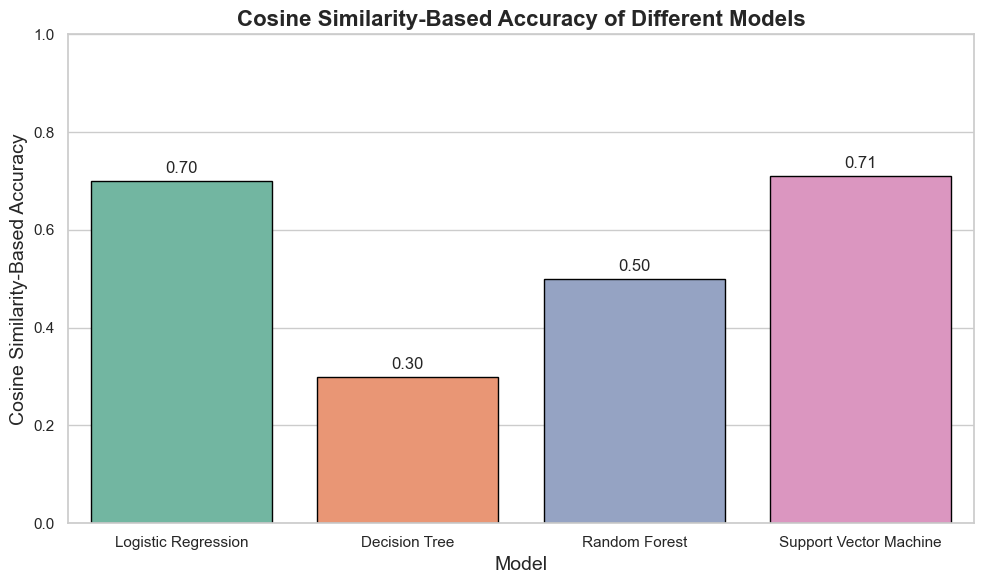

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

#assuming we already have cosine similarity-based accuracy for each model
#cosine similarity accuracies for the models (just an example, replace these values with the actual results from your model)
cosine_accuracies = {
    'Logistic Regression': 0.70,
    'Decision Tree': 0.30,
    'Random Forest': 0.50,
    'Support Vector Machine': 0.71
}

#convert to DataFrame for easier plotting
accuracy_df = pd.DataFrame(list(cosine_accuracies.items()), columns=['Model', 'Cosine Similarity-Based Accuracy'])

#set the plot size and style
plt.figure(figsize=(10, 6))
sns.set(style="whitegrid")

#create a bar plot
barplot = sns.barplot(x='Model', y='Cosine Similarity-Based Accuracy', data=accuracy_df, palette='Set2', edgecolor='black')

#add title and labels
plt.title('Cosine Similarity-Based Accuracy of Different Models', fontsize=16, fontweight='bold')
plt.xlabel('Model', fontsize=14)
plt.ylabel('Cosine Similarity-Based Accuracy', fontsize=14)

#customize the y-axis limits
plt.ylim(0, 1)

#annotate the accuracy values on top of the bars
for p in barplot.patches:
    barplot.annotate(format(p.get_height(), '.2f'), 
                     (p.get_x() + p.get_width() / 2., p.get_height()), 
                     ha='center', va='center', 
                     xytext=(0, 9), textcoords='offset points', fontsize=12)

#show the plot
plt.tight_layout()
plt.show()


Step 7: Testing the prediction of models on custom ingredients

In [25]:
#predicting with custom ingredients
def predict_recipe(custom_ingredients_list):
    predictions = {}  # Dictionary to hold predictions for all input sets

    #loop through each set of ingredients
    for custom_ingredients in custom_ingredients_list:
        #preprocess the input
        processed_ingredients = preprocess_ingredients(custom_ingredients)
        
        #transform using the same vectorizer
        custom_tfidf = vectorizer.transform([processed_ingredients])
        
        #make predictions for each model
        predictions[custom_ingredients] = {}  #initialize a sub-dictionary for the current ingredients
        for model_name, model in models.items():
            pred = model.predict(custom_tfidf)
            predictions[custom_ingredients][model_name] = pred[0]  #store the predicted recipe name
    
    return predictions

#example custom ingredients input
custom_ingredients_list = [
    "vegetables, mutton, garlic, ginger",
    "milk, sugar, flour, rice",
    "coconut, eggs, flour",
    "potatoes, olive oil, cheese, soy sauce"
]  

#get predictions for all ingredient sets
predicted_recipes = predict_recipe(custom_ingredients_list)

#print the predictions
for ingredients, preds in predicted_recipes.items():
    print(f'Predicted Recipes for "{ingredients}":')
    for model_name, recipe in preds.items():
        print(f'  {model_name}: {recipe}')


Predicted Recipes for "vegetables, mutton, garlic, ginger":
  Logistic Regression: Meat Saag Gosht
  Decision Tree: Chutney Sandwich
  Random Forest: Beef Tamatar Gosht
  Support Vector Machine: Meat Saag Gosht
Predicted Recipes for "milk, sugar, flour, rice":
  Logistic Regression: Bakar Khani
  Decision Tree: Boondi Phirni
  Random Forest: Kheer Pancakes
  Support Vector Machine: Bakar Khani
Predicted Recipes for "coconut, eggs, flour":
  Logistic Regression: Coconut Macaroon Cake
  Decision Tree: Lemon & Coconut Bars
  Random Forest: Coconut Rice Pudding
  Support Vector Machine: Coconut Macaroon Cake
Predicted Recipes for "potatoes, olive oil, cheese, soy sauce":
  Logistic Regression: BBQ Fish & Roasted Garlic Potatoes
  Decision Tree: BBQ Potato Wedges
  Random Forest: Grilled Paneer & Zucchini Skewers
  Support Vector Machine: BBQ Fish & Roasted Garlic Potatoes
